# OptiCrop – Model Ensembling & Accuracy Optimization
Builds on the foundation EDA notebook. Goal: combine multiple models (ensembling) and tune hyperparameters to push accuracy beyond the single best baseline model (Random Forest).

## 1. Setup & Reload Data
Re-running the same split/scaling as the foundation notebook so results are comparable.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import joblib

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("Crop_recommendation.csv")
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

X = df[features]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1760, 7)  Test: (440, 7)


## 2. Baseline Recap
Same 4 models as before, as a reference point to beat.

In [2]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}

baseline_results = {}
for name, model in baseline_models.items():
    if name in ["Logistic Regression", "KNN"]:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    baseline_results[name] = {"accuracy": acc, "macro_f1": f1}

pd.DataFrame(baseline_results).T.sort_values("accuracy", ascending=False)

,accuracy,macro_f1
Random Forest,0.995455,0.995452
Decision Tree,0.979545,0.979423
KNN,0.979545,0.979283
Logistic Regression,0.972727,0.972464


## 3. Hyperparameter Tuning
Tune the top individual models with `GridSearchCV` before combining them — ensembling weak/untuned models rarely beats a well-tuned single model, so this step matters.

In [3]:
# Random Forest tuning
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid,
                        cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train, y_train)

print("Best RF params:", rf_grid.best_params_)
print("Best RF CV accuracy:", rf_grid.best_score_)
best_rf = rf_grid.best_estimator_

Best RF params: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Best RF CV accuracy: 0.9960227272727271


In [4]:
# KNN tuning
knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
}

knn_grid = GridSearchCV(KNeighborsClassifier(), knn_param_grid,
                         cv=5, scoring='accuracy', n_jobs=-1)
knn_grid.fit(X_train_scaled, y_train)

print("Best KNN params:", knn_grid.best_params_)
print("Best KNN CV accuracy:", knn_grid.best_score_)
best_knn = knn_grid.best_estimator_

Best KNN params: {'n_neighbors': 3, 'weights': 'distance'}
Best KNN CV accuracy: 0.9715909090909092


In [5]:
# SVM (new candidate — often strong on this dataset, worth adding for the ensemble)
svm_param_grid = {
    'C': [1, 10, 100],
    'gamma': ['scale', 0.1, 0.01],
    'kernel': ['rbf'],
}

svm_grid = GridSearchCV(SVC(probability=True, random_state=42), svm_param_grid,
                         cv=5, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)

print("Best SVM params:", svm_grid.best_params_)
print("Best SVM CV accuracy:", svm_grid.best_score_)
best_svm = svm_grid.best_estimator_

Best SVM params: {'C': 100, 'gamma': 0.1, 'kernel': 'rbf'}
Best SVM CV accuracy: 0.9869318181818182


In [6]:
# Gradient Boosting (new candidate — another strong tree-ensemble base learner)
gb = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
gb_preds = gb.predict(X_test)
print("Gradient Boosting test accuracy:", accuracy_score(y_test, gb_preds))

Gradient Boosting test accuracy: 0.9886363636363636


## 4. Tuned Individual Models — Test Set Comparison

In [8]:
tuned_results = {}

# RF (unscaled)
preds = best_rf.predict(X_test)
tuned_results["Random Forest (tuned)"] = {
    "accuracy": accuracy_score(y_test, preds),
    "macro_f1": f1_score(y_test, preds, average='macro')
}

# KNN (scaled)
preds = best_knn.predict(X_test_scaled)
tuned_results["KNN (tuned)"] = {
    "accuracy": accuracy_score(y_test, preds),
    "macro_f1": f1_score(y_test, preds, average='macro')
}

# SVM (scaled)
preds = best_svm.predict(X_test_scaled)
tuned_results["SVM (tuned)"] = {
    "accuracy": accuracy_score(y_test, preds),
    "macro_f1": f1_score(y_test, preds, average='macro')
}

# Gradient Boosting (unscaled)
tuned_results["Gradient Boosting"] = {
    "accuracy": accuracy_score(y_test, gb_preds),
    "macro_f1": f1_score(y_test, gb_preds, average='macro')
}

tuned_df = pd.DataFrame(tuned_results).T.sort_values("accuracy", ascending=False)
tuned_df

,accuracy,macro_f1
Random Forest (tuned),0.995455,0.995452
SVM (tuned),0.988636,0.988621
Gradient Boosting,0.988636,0.988674
KNN (tuned),0.975000,0.974766


## 5. Ensembling — Voting Classifier
Combines RF, KNN, and SVM via **soft voting** (averages predicted probabilities). Since RF/GB don't need scaling but KNN/SVM do, we scale everything here for consistency inside the ensemble (tree models are not hurt by scaling, just don't need it).

In [9]:
voting_clf = VotingClassifier(
    estimators=[
        ('rf', best_rf),
        ('knn', best_knn),
        ('svm', best_svm),
    ],
    voting='soft'
)

voting_clf.fit(X_train_scaled, y_train)
voting_preds = voting_clf.predict(X_test_scaled)

voting_acc = accuracy_score(y_test, voting_preds)
voting_f1 = f1_score(y_test, voting_preds, average='macro')

print(f"Voting Classifier — accuracy: {voting_acc:.4f}, macro F1: {voting_f1:.4f}")

Voting Classifier — accuracy: 0.9932, macro F1: 0.9932


## 6. Ensembling — Stacking Classifier
Trains a meta-model (Logistic Regression) on top of the base models' predictions. Often edges out voting since it *learns* how to weight each base model rather than averaging blindly.

In [10]:
stacking_clf = StackingClassifier(
    estimators=[
        ('rf', best_rf),
        ('knn', best_knn),
        ('svm', best_svm),
        ('gb', gb),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1
)

stacking_clf.fit(X_train_scaled, y_train)
stacking_preds = stacking_clf.predict(X_test_scaled)

stacking_acc = accuracy_score(y_test, stacking_preds)
stacking_f1 = f1_score(y_test, stacking_preds, average='macro')

print(f"Stacking Classifier — accuracy: {stacking_acc:.4f}, macro F1: {stacking_f1:.4f}")

Stacking Classifier — accuracy: 0.9977, macro F1: 0.9977


## 7. Final Comparison — All Models

In [11]:
final_results = dict(tuned_results)
final_results["Voting Ensemble"] = {"accuracy": voting_acc, "macro_f1": voting_f1}
final_results["Stacking Ensemble"] = {"accuracy": stacking_acc, "macro_f1": stacking_f1}

final_df = pd.DataFrame(final_results).T.sort_values("accuracy", ascending=False)
final_df

,accuracy,macro_f1
Stacking Ensemble,0.997727,0.997726
Random Forest (tuned),0.995455,0.995452
Voting Ensemble,0.993182,0.993169
SVM (tuned),0.988636,0.988621
Gradient Boosting,0.988636,0.988674
KNN (tuned),0.975000,0.974766


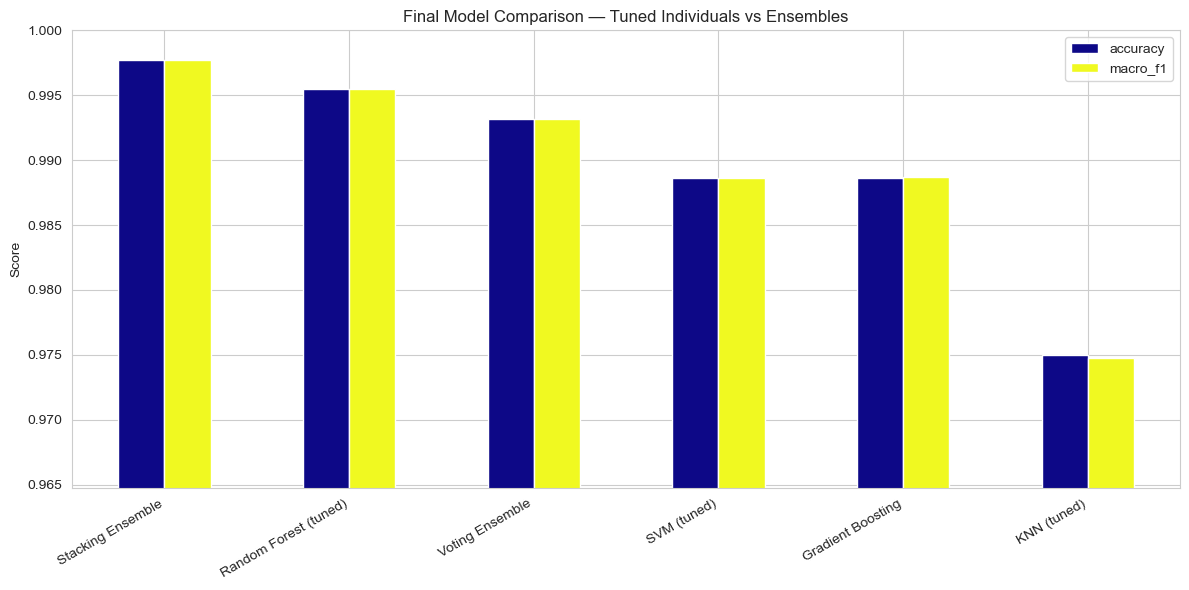

In [12]:
final_df.plot(kind='bar', figsize=(12, 6), colormap='plasma')
plt.title("Final Model Comparison — Tuned Individuals vs Ensembles")
plt.ylabel("Score")
plt.xticks(rotation=30, ha='right')
plt.ylim(min(final_df.min())-0.01, 1.0)
plt.tight_layout()
plt.show()

## 8. Best Overall Model — Detailed Evaluation

In [13]:
best_name = final_df["accuracy"].idxmax()
print("Best overall model:", best_name)

model_lookup = {
    "Random Forest (tuned)": (best_rf, X_test),
    "KNN (tuned)": (best_knn, X_test_scaled),
    "SVM (tuned)": (best_svm, X_test_scaled),
    "Gradient Boosting": (gb, X_test),
    "Voting Ensemble": (voting_clf, X_test_scaled),
    "Stacking Ensemble": (stacking_clf, X_test_scaled),
}

best_final_model, best_final_X_test = model_lookup[best_name]
best_final_preds = best_final_model.predict(best_final_X_test)

print(classification_report(y_test, best_final_preds))

Best overall model: Stacking Ensemble
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00

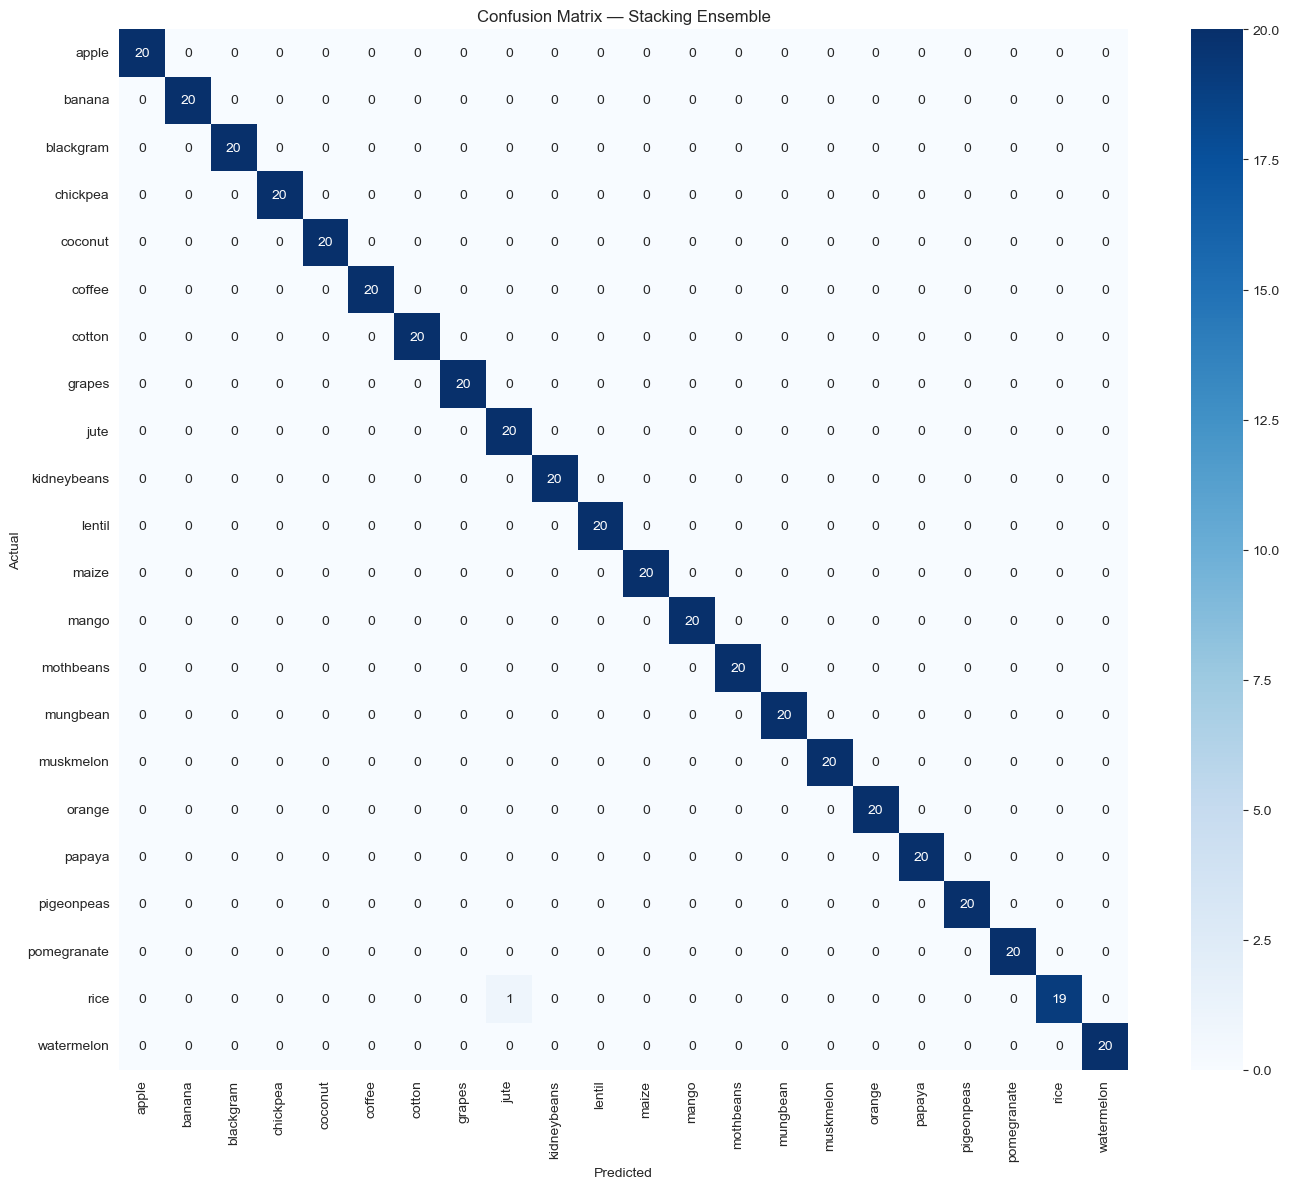

In [14]:
cm = confusion_matrix(y_test, best_final_preds, labels=sorted(y.unique()))
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()), yticklabels=sorted(y.unique()))
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Save Best Model
Exports whichever model (single or ensemble) performed best, plus the scaler, for the backend.

In [15]:
joblib.dump(best_final_model, "crop_model_best.joblib")
joblib.dump(scaler, "scaler.joblib")

import json
metrics = {
    "best_model": best_name,
    "accuracy": final_results[best_name]["accuracy"],
    "macro_f1": final_results[best_name]["macro_f1"],
    "all_results": final_results,
    "note": "Model requires scaled input if best_model is KNN/SVM/Voting/Stacking; Random Forest/GB use raw features."
}
with open("model_metrics_ensemble.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved crop_model_best.joblib, scaler.joblib, model_metrics_ensemble.json")
print(f"\nBest model: {best_name}")
print(f"Accuracy: {final_results[best_name]['accuracy']:.4f}")
print(f"Macro F1: {final_results[best_name]['macro_f1']:.4f}")

Saved crop_model_best.joblib, scaler.joblib, model_metrics_ensemble.json

Best model: Stacking Ensemble
Accuracy: 0.9977
Macro F1: 0.9977
